# AgriPulse 03: Shock recipes (association rules)

Each crop-year becomes a *transaction* of discretised items: temperature anomaly, rainfall deviation,
climate zone, pesticide level and change, last year's outcome, crop group, region, and the label
`SHOCK`. Frequent itemsets are mined with **Apriori** (and checked against **FP-growth**). Rules of the
form `{conditions} → {SHOCK}` are ranked by **lift**, the factor by which the conditions raise the
shock rate above its base rate.

| measure | meaning here |
|---|---|
| support | share of all crop-years that match the conditions *and* are shocks |
| confidence | P(shock \| conditions), the shock rate inside the rule |
| lift | confidence / overall shock rate (lift > 1 means more shocks than usual) |

In [1]:
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

from agripulse import config as cfg, mining as mn, plotting as viz
from agripulse.data import load_ml_dataset

viz.apply_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.3f}".format)
TABLES = ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

In [2]:
ml = mn.prepare(load_ml_dataset())
T = mn.transactions(ml)
base_rate = T["SHOCK"].mean()
print(f"{len(T):,} transactions, {T.shape[1]} items, base shock rate {base_rate:.1%}")

support = T.mean().rename("support").to_frame()
support["attribute"] = [c.split("=")[0] if "=" in c else "label" for c in support.index]
support.sort_values(["attribute", "support"], ascending=[True, False])

16,339 transactions, 32 items, base shock rate 10.2%


,support,attribute
climate=Humid,0.441,climate
climate=Sub-humid,0.273,climate
climate=Very humid,0.120,climate
climate=Semi-arid,0.091,climate
climate=Arid,0.076,climate
crop_group=Cereals,0.510,crop_group
crop_group=Roots & Tubers,0.354,crop_group
crop_group=Oilseeds,0.098,crop_group
crop_group=Starchy Fruits,0.038,crop_group
NO_SHOCK,0.898,label


**Rainfall carries no information here.** `rain=normal` is present in almost every transaction
(see notebook 01: the source rainfall is a static long-term average), so it is removed before mining,
together with `NO_SHOCK`, which is only the complement of the label.

In [3]:
uninformative = support.index[support.support >= 0.99].tolist()
print("removed:", uninformative + ["NO_SHOCK"])
items = T.drop(columns=uninformative + ["NO_SHOCK"])

MIN_SUPPORT, MAX_LEN = 0.005, 4   # 0.5 % of 16k crop-years is about 80 rows
t0 = time.perf_counter()
fi_ap = apriori(items, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
t_ap = time.perf_counter() - t0
t0 = time.perf_counter()
fi_fp = fpgrowth(items, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
t_fp = time.perf_counter() - t0
print(f"Apriori : {len(fi_ap):,} frequent itemsets in {t_ap:.2f} s")
print(f"FP-growth: {len(fi_fp):,} frequent itemsets in {t_fp:.2f} s")
print("identical itemsets:", set(fi_ap.itemsets) == set(fi_fp.itemsets))

removed: ['rain=normal', 'NO_SHOCK']


Apriori : 3,271 frequent itemsets in 0.29 s
FP-growth: 3,271 frequent itemsets in 0.31 s
identical itemsets: True


In [4]:
def shock_rules(frequent, n_rows):
    rules = association_rules(frequent, metric="lift", min_threshold=1.0)
    rules = rules[rules.consequents == frozenset({"SHOCK"})].copy()
    rules["rule"] = rules.antecedents.map(lambda s: " AND ".join(sorted(s)))
    rules["n_items"] = rules.antecedents.map(len)
    rules["shock_rows"] = (rules.support * n_rows).round().astype(int)
    return (rules[["rule", "n_items", "support", "confidence", "lift", "shock_rows"]]
            .sort_values("lift", ascending=False).reset_index(drop=True))

rules = shock_rules(fi_ap, len(items))
rules.to_csv(TABLES / "association_rules_shock_all.csv", index=False)
print(f"{len(rules):,} rules with consequent SHOCK and lift > 1")
rules.head(15)

203 rules with consequent SHOCK and lift > 1


,rule,n_items,support,confidence,lift,shock_rows
0,climate=Humid AND crop_group=Roots & Tubers AND last_year=shock,3,0.006,0.500,4.901,106
1,climate=Humid AND last_year=shock AND pesticide=low,3,0.009,0.495,4.853,153
2,climate=Humid AND last_year=shock AND region=Sub-Saharan Africa,3,0.012,0.495,4.850,191
3,crop_group=Roots & Tubers AND last_year=shock AND pesticide=low,3,0.006,0.490,4.801,96
4,crop_group=Roots & Tubers AND last_year=shock AND region=Sub-Saharan Africa,3,0.007,0.489,4.792,110
5,last_year=shock AND pesticide=low AND region=Sub-Saharan Africa,3,0.015,0.477,4.674,247
6,climate=Humid AND last_year=shock AND temp=warm(+0.5..1C),3,0.007,0.473,4.641,116
7,last_year=shock AND pesticide=low AND pesticide_change=stable,3,0.013,0.473,4.634,217
8,last_year=shock AND pesticide=low,2,0.019,0.461,4.523,305
9,last_year=shock AND pesticide=low AND temp=warm(+0.5..1C),3,0.007,0.460,4.509,121


## 1. Climate and input recipes only

The strongest rules above lean on `last_year=shock` and on region. To answer *which combinations of
climate stress produce shocks*, the antecedent is restricted to climate and input items: temperature
anomaly, climate zone, pesticide level and pesticide change.

In [5]:
CLIMATE_PREFIXES = ("temp=", "rain=", "climate=", "pesticide=", "pesticide_change=")

def climate_only(rules):
    keep = rules.rule.map(lambda r: all(i.startswith(CLIMATE_PREFIXES) for i in r.split(" AND ")))
    return rules[keep.astype(bool)].reset_index(drop=True)

recipes = climate_only(rules)
recipes.to_csv(TABLES / "association_rules_shock_climate.csv", index=False)
recipes.head(15)

,rule,n_items,support,confidence,lift,shock_rows
0,climate=Semi-arid AND pesticide=low AND pesticide_change=stable,3,0.006,0.222,2.171,105
1,climate=Semi-arid AND pesticide=low,2,0.007,0.203,1.990,119
2,climate=Semi-arid AND pesticide_change=stable,2,0.013,0.179,1.752,220
3,climate=Arid AND pesticide=low,2,0.006,0.178,1.748,97
4,climate=Semi-arid AND temp=warm(+0.5..1C),2,0.005,0.175,1.710,89
5,climate=Semi-arid,1,0.016,0.172,1.689,256
6,pesticide=medium AND temp=hot(>+1C),2,0.010,0.168,1.642,162
7,climate=Sub-humid AND pesticide=low,2,0.007,0.167,1.641,116
8,pesticide=medium AND pesticide_change=stable AND temp=hot(>+1C),3,0.007,0.154,1.514,118
9,climate=Semi-arid AND pesticide=high,2,0.005,0.153,1.499,87


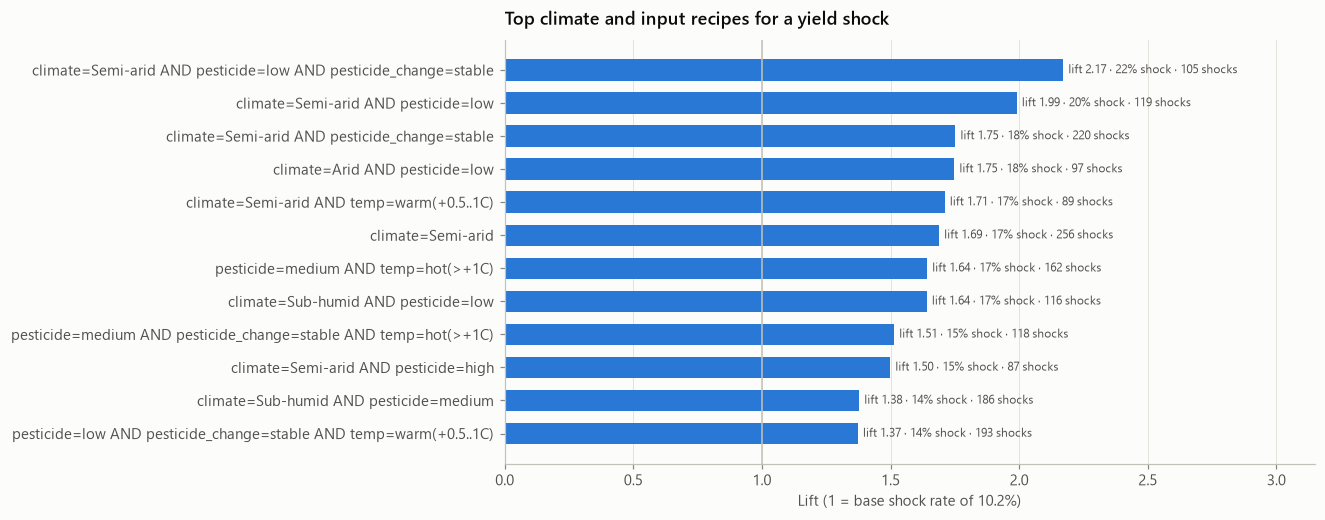

In [6]:
top = recipes.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.barh(top.rule, top.lift, color=viz.SERIES[0], height=0.65)
for y, (l, c, n) in enumerate(zip(top.lift, top.confidence, top.shock_rows)):
    ax.text(l + 0.02, y, f"lift {l:.2f} · {c:.0%} shock · {n} shocks", va="center", fontsize=8,
            color=viz.INK_2)
ax.axvline(1, color=viz.AXIS, lw=1)
ax.set_xlim(0, top.lift.max() * 1.45)
ax.set(title="Top climate and input recipes for a yield shock",
       xlabel=f"Lift (1 = base shock rate of {base_rate:.1%})")
ax.grid(axis="y", visible=False)
viz.save(fig, "fig15_shock_recipes")
plt.show()

## 2. Do the recipes differ by crop group and region?

Rules are mined again *inside* each crop group and each region, so lift is measured against that group's
own shock rate. Only climate and input items are allowed in the antecedent, and a rule must cover at
least 30 shock crop-years.

In [7]:
def recipes_within(dim, top_n=3, min_rows=30):
    out = []
    for key, g in ml.groupby(dim):
        Tg = mn.transactions(g)
        drop = [c for c in Tg.columns if Tg[c].mean() >= 0.99 or c == "NO_SHOCK"
                or c.startswith(("crop_group=", "region=", "last_year="))]
        Tg = Tg.drop(columns=drop)
        if "SHOCK" not in Tg or Tg.SHOCK.sum() < min_rows:
            continue
        fi = apriori(Tg, min_support=min_rows / len(Tg), use_colnames=True, max_len=4)
        r = climate_only(shock_rules(fi, len(Tg)))
        r = r[r.shock_rows >= min_rows].head(top_n)
        if r.empty:
            continue
        r.insert(0, "group_shock_rate", Tg.SHOCK.mean())
        r.insert(0, dim, key)
        out.append(r)
    return pd.concat(out, ignore_index=True)

by_crop_group = recipes_within("crop_group")
by_region = recipes_within("region")
pd.concat([by_crop_group.rename(columns={"crop_group": "group"}).assign(dimension="crop group"),
           by_region.rename(columns={"region": "group"}).assign(dimension="region")]).to_csv(
    TABLES / "association_rules_by_group.csv", index=False)
by_crop_group

,crop_group,group_shock_rate,rule,n_items,support,confidence,lift,shock_rows
0,Cereals,0.121,climate=Arid AND pesticide=low AND temp=near-normal,3,0.005,0.348,2.886,40
1,Cereals,0.121,climate=Semi-arid AND temp=cooler,2,0.004,0.301,2.497,31
2,Cereals,0.121,climate=Semi-arid AND pesticide=low AND temp=warm(+0.5..1C),3,0.005,0.288,2.387,42
3,Oilseeds,0.126,pesticide=medium AND temp=hot(>+1C),2,0.020,0.269,2.127,32
4,Oilseeds,0.126,climate=Sub-humid AND pesticide=medium,2,0.019,0.223,1.764,31
5,Oilseeds,0.126,temp=hot(>+1C),1,0.041,0.210,1.664,65
6,Roots & Tubers,0.073,climate=Sub-humid AND pesticide=low,2,0.005,0.138,1.882,30
7,Roots & Tubers,0.073,pesticide=low AND pesticide_change=stable AND temp=warm(+0.5..1C),3,0.010,0.120,1.640,56
8,Roots & Tubers,0.073,climate=Humid AND pesticide=medium AND temp=warm(+0.5..1C),3,0.006,0.110,1.505,33


In [8]:
by_region

,region,group_shock_rate,rule,n_items,support,confidence,lift,shock_rows
0,East Asia & Pacific,0.043,climate=Humid,1,0.025,0.046,1.063,41
1,Europe & Central Asia,0.115,climate=Semi-arid AND pesticide=medium,2,0.009,0.204,1.774,33
2,Europe & Central Asia,0.115,climate=Semi-arid,1,0.024,0.202,1.758,85
3,Europe & Central Asia,0.115,climate=Semi-arid AND pesticide_change=stable,2,0.019,0.196,1.711,67
4,Latin America & Caribbean,0.073,pesticide_change=cut(<-20%),1,0.012,0.151,2.069,45
5,Latin America & Caribbean,0.073,climate=Very humid AND pesticide=low AND temp=near-normal,3,0.010,0.107,1.466,37
6,Latin America & Caribbean,0.073,climate=Very humid AND pesticide=low AND pesticide_change=stable,3,0.012,0.098,1.348,46
7,Middle East & North Africa,0.115,climate=Semi-arid AND pesticide=high AND pesticide_change=stable,3,0.028,0.214,1.867,36
8,Middle East & North Africa,0.115,climate=Semi-arid AND pesticide=high,2,0.028,0.214,1.867,36
9,Middle East & North Africa,0.115,climate=Arid AND pesticide=low AND pesticide_change=stable,3,0.037,0.174,1.517,47


## 3. Takeaways

* **Apriori and FP-growth agree:** 3,271 identical frequent itemsets (minimum support 0.5 %). FP-growth
  is marginally faster at this size (0.26 s vs 0.30 s).
* **`rain=normal` has 100 % support** and was removed: the rainfall source cannot produce a drought
  item.
* **The strongest recipes all include `last_year=shock`:** lift 4.3-4.9 and 45-50 % confidence,
  combined with low pesticide use, Sub-Saharan Africa, humid climate or roots & tubers.
* **Climate and input recipes are weaker but readable** (lift up to 2.2):
  * semi-arid climate + low pesticide use → 20-22 % shocks (lift 2.0-2.2)
  * arid climate + low pesticide use → 17.8 % (lift 1.75)
  * medium pesticide use + anomaly above +1 °C → 16.8 % (lift 1.64)
  * anomaly above +1 °C alone → 13.0 % (lift 1.27)
  * pesticide use cut by more than 20 % → 13.5 % (lift 1.33)
* **The recipe depends on the crop.** For cereals, aridity plus low pesticide use (lift 2.4-2.9). For
  oilseeds (soybeans), heat: an anomaly above +1 °C (lift 1.7-2.1). For roots & tubers, only weak
  patterns (lift ≤ 1.9).
* **The recipe depends on the region.** In Sub-Saharan Africa, sub-humid climate with low pesticide use
  (30-34 % shocks, lift 2.0-2.4). In Europe & Central Asia and in the Middle East & North Africa,
  semi-arid climate (lift 1.8-1.9). In Latin America, cuts in pesticide use of more than 20 % (lift 2.1).
  East Asia & Pacific shows no recipe (best lift 1.06). North America and South Asia have fewer than 30
  shocks, so they were not mined.